In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
Animal = pd.DataFrame(pd.read_csv('data/animal_c.csv'))
df = pd.DataFrame(pd.read_csv('data/changes-residential-duration-covid.csv'))

In [3]:

pandemia_casa = df[df['Entity'] == 'Spain'].copy()
pandemia_casa['Day'] = pd.to_datetime(pandemia_casa['Day'])
pandemia_casa_sincols = pandemia_casa.drop(columns='Code')
pandemia_casa_sincols_def = pandemia_casa_sincols.drop(columns='Entity')



In [4]:

pandemia_casa_sincols_def

,Day,Residential
106747,2020-02-17,-1.667
106748,2020-02-18,-1.250
106749,2020-02-19,-1.200
106750,2020-02-20,-1.167
106751,2020-02-21,-1.286
...,...,...
107714,2022-10-11,-0.571
107715,2022-10-12,1.429
107716,2022-10-13,1.571
107717,2022-10-14,1.571


In [5]:
Animal['Time'] = pd.to_datetime(Animal['Time'])
Animal = Animal.set_index('Time')
Animal.loc['2020']

,Animal Crossing
Time,
2020-01-05,4
2020-01-12,4
2020-01-19,4
2020-01-26,6
2020-02-02,7
2020-02-09,6
2020-02-16,11
2020-02-23,13
2020-03-01,12


In [6]:
casa = pandemia_casa_sincols_def.set_index('Day')
casa_2020 = casa.loc['2020']
casa_2020.shape

(319, 1)

In [7]:
casa_semanal = casa_2020.resample('W-SUN', label='left', closed='left').mean()
casa_semanal.head()

,Residential
Day,
2020-02-16,-1.309333
2020-02-23,-1.081714
2020-03-01,-0.428571
2020-03-08,0.367429
2020-03-15,16.469286


In [8]:
juntos = casa_semanal.join(Animal, how='inner')
print(juntos.shape)
juntos.corr()

(46, 2)


,Residential,Animal Crossing
Residential,1.000000,0.890319
Animal Crossing,0.890319,1.000000


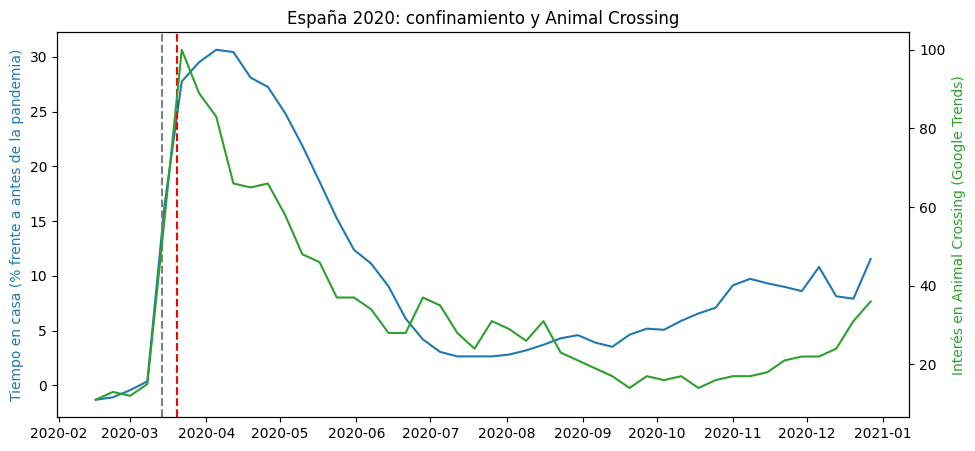

In [9]:
fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(juntos.index, juntos['Residential'], color='tab:blue')
ax1.set_ylabel('Tiempo en casa (% frente a antes de la pandemia)', color='tab:blue')

ax2 = ax1.twinx()
ax2.plot(juntos.index, juntos['Animal Crossing'], color='tab:green')
ax2.set_ylabel('Interés en Animal Crossing (Google Trends)', color='tab:green')

ax1.axvline(pd.Timestamp('2020-03-14'), color='grey', linestyle='--')  # estado de alarma
ax1.axvline(pd.Timestamp('2020-03-20'), color='red', linestyle='--')   # lanzamiento

plt.title('España 2020: confinamiento y Animal Crossing')
plt.show()

In [22]:
#LIMPIAR DATASET PISA

pisa_data = pd.DataFrame(pd.read_csv('data/pisa.csv'))
pisa_ue_25 = pd.DataFrame(pd.read_csv('data/PISA_2025_UE.csv'))

In [20]:
pisa_data

,Entity,Code,Year,Reading
0,Albania,ALB,2000,348.84952
1,Albania,ALB,2009,384.81660
2,Albania,ALB,2012,393.96426
3,Albania,ALB,2015,405.25876
4,Albania,ALB,2018,405.42935
...,...,...,...,...
489,Uruguay,URY,2022,430.35970
490,Uzbekistan,UZB,2022,335.50490
491,Vietnam,VNM,2012,508.21900
492,Vietnam,VNM,2015,486.77377


In [ ]:
ue = ['Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Czechia', 'Denmark',
      'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Ireland',
      'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Netherlands', 'Poland',
      'Portugal', 'Romania', 'Slovakia', 'Slovenia', 'Spain', 'Sweden']  #sacar paises de la UE a una lista

pisa_data_total = pd.concat([pisa_data, pisa_ue_25]) #concatenar datasets de datos generales con los de UE 2025

pisa_data_total_ue = pisa_data_total[pisa_data_total['Entity'].isin(ue)] #limpiar dataset completo con solo paises de ala UE incluyendo datos 2025
pisa_data_total_ue = pisa_data_total_ue.sort_values(['Entity', 'Year'])



,Entity,Code,Year,Reading
22,Austria,AUT,2000,492.05600
23,Austria,AUT,2003,490.69324
24,Austria,AUT,2006,490.19397
25,Austria,AUT,2009,470.28363
26,Austria,AUT,2012,489.60934
...,...,...,...,...
422,Sweden,SWE,2012,483.33500
423,Sweden,SWE,2015,500.15560
424,Sweden,SWE,2018,505.78522
425,Sweden,SWE,2022,486.97516


In [44]:
pisa_espanita = pisa_data_total_ue[pisa_data_total_ue['Entity'] == 'Spain'] #Sacar datos solo de Españita
pisa_espanita
espanita_serie = pisa_espanita.set_index('Year')['Reading']
espanita_serie

Year
2000    492.55298
2003    480.53800
2006    460.83010
2009    481.04233
2012    487.93918
2015    495.57645
2022    474.30710
2025    451.00000
Name: Reading, dtype: float64

In [ ]:
ediciones = pisa_data_total_ue[pisa_data_total_ue['Year'] <= 2022].groupby('Entity')['Year'].count()
paises_completos = ediciones[ediciones == 8].index #sacar la media de resultados por pais y por año

ue15 = (pisa_data_total_ue[pisa_data_total_ue['Entity'].isin(paises_completos)]
        .groupby('Year')['Reading'].mean())
ue15

Year
2000    494.294313
2003    495.589177
2006    492.832146
2009    493.866673
2012    498.732513
2015    495.944322
2018    493.031649
2022    481.093112
2025    463.000000
Name: Reading, dtype: float64

In [36]:
ue15.index

Index([2000, 2003, 2006, 2009, 2012, 2015, 2018, 2022, 2025], dtype='int64', name='Year')

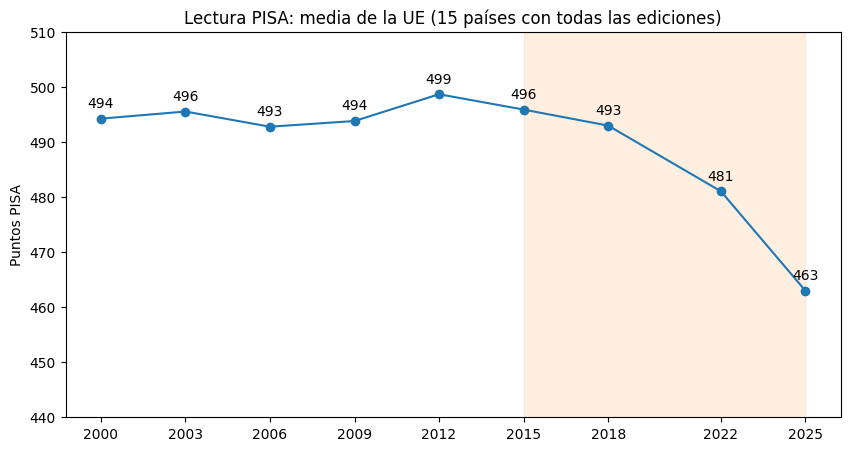

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))  #generar marco del grafico
ax.plot(ue15.index, ue15.values, marker='o', color='tab:blue') #establecer eje X = index(año del estudio), y = valor de los datos
ax.axvspan(2015, 2025, color='tab:orange', alpha=0.12) #introducir franja naranja para destacar periodo del origen del smartphone  
for anio, nota in ue15.items():
    ax.annotate(f'{nota:.0f}', (anio, nota), textcoords='offset points', xytext=(0, 8), ha='center') #pintar la nota sobre cada punto
ax.set_ylim(440, 510) #establecer limite del eje y
ax.set_xticks(ue15.index) #dividir en cachitos el eje x.
ax.set_title('Lectura PISA: media de la UE (15 países con todas las ediciones)') #establecer title del grafico
ax.set_ylabel('Puntos PISA') #establecer title del eje y
plt.show() #lanzar grafico

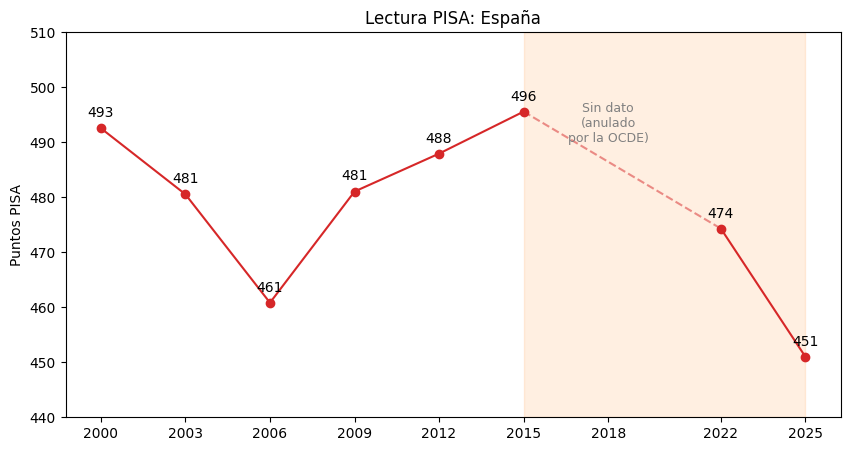

In [ ]:
anios = [2000, 2003, 2006, 2009, 2012, 2015, 2018, 2022, 2025]  
espana_completa = espanita_serie.reindex(anios)   #reindexar el dataset con años separado, se reintegra el index con estos nuevos valores

fig, ax = plt.subplots(figsize=(10, 5))  #crear cuadro
ax.plot(espana_completa.index, espana_completa.values, marker='o', color='tab:red')  #establecer x = indice del dataset (anios), y = valores del dataset
ax.plot([2015, 2022], [espanita_serie[2015], espanita_serie[2022]],
        linestyle='--', color='tab:red', alpha=0.5)  #dibujar linea con transparencia 0.5 para representar datos faltantes
ax.axvspan(2015, 2025, color='tab:orange', alpha=0.12)  #establecer franja naranja para representar caida acentuada
for anio, nota in espanita_serie.items():
    ax.annotate(f'{nota:.0f}', (anio, nota), textcoords='offset points', xytext=(0, 8), ha='center') #establecer anotaciones con los valores sobre cada punto
ax.text(2018, 490, 'Sin dato\n(anulado\npor la OCDE)', ha='center', fontsize=9, color='grey')  #comentario fijado para datos faltantes
ax.set_ylim(440, 510)
ax.set_xticks(anios)
ax.set_title('Lectura PISA: España')
ax.set_ylabel('Puntos PISA')
plt.show()  #limites, labels lanzar el grafico

,UE,España,Diferencia
Year,,,
2000,494.3,492.6,-1.7
2003,495.6,480.5,-15.1
2006,492.8,460.8,-32.0
2009,493.9,481.0,-12.8
2012,498.7,487.9,-10.8
2015,495.9,495.6,-0.4
2022,481.1,474.3,-6.8
2025,463.0,451.0,-12.0


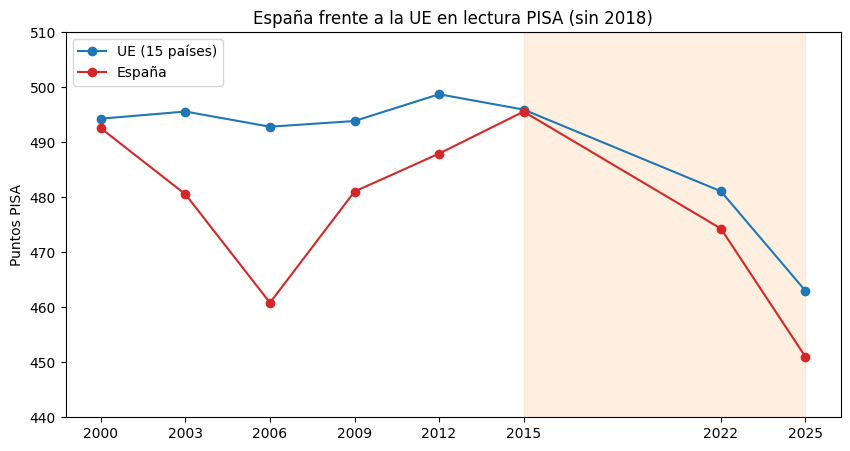

In [ ]:
comparacion = pd.DataFrame({'UE': ue15, 'España': espana_completa}).dropna()   # el dropna quita 2018
comparacion['Diferencia'] = comparacion['España'] - comparacion['UE']    #Crear un diccionario con la comparacion entre valores de españita y UE
display(comparacion.round(1))

fig, ax = plt.subplots(figsize=(10, 5)) 
ax.plot(comparacion.index, comparacion['UE'], marker='o', label='UE (15 países)')
ax.plot(comparacion.index, comparacion['España'], marker='o', color='tab:red', label='España')  #representar valores de ambos datasets para comparacion grafica
ax.axvspan(2015, 2025, color='tab:orange', alpha=0.12) #zona naranja habitual para representar zona de caída
ax.set_ylim(440, 510)
ax.set_xticks(comparacion.index)
ax.set_title('España frente a la UE en lectura PISA (sin 2018)')
ax.set_ylabel('Puntos PISA')
ax.legend() #limites, labels y lanzar el gráfico
plt.show()

In [60]:
pisa_maths_ue_25 = pd.DataFrame(pd.read_csv('data/PISA_2025_UE_matematicas.csv'))
pisa_maths = pd.DataFrame(pd.read_csv('data/matematics.csv'))
ue = ['Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Czechia', 'Denmark',
      'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Ireland',
      'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Netherlands', 'Poland',
      'Portugal', 'Romania', 'Slovakia', 'Slovenia', 'Spain', 'Sweden']
pisa_maths_general = pd.concat([pisa_maths, pisa_maths_ue_25])

pisa_maths_general = pisa_maths_general[pisa_maths_general['Entity'].isin(ue)]

pisa_maths_general


,Entity,Code,Year,Mathematics
19,Austria,AUT,2003,505.61100
20,Austria,AUT,2006,505.48360
21,Austria,AUT,2009,495.90866
22,Austria,AUT,2012,505.54074
23,Austria,AUT,2015,496.74228
...,...,...,...,...
22,Romania,ROU,2025,419.00000
23,Slovakia,SVK,2025,469.00000
24,Slovenia,SVN,2025,460.00000
25,Spain,ESP,2025,457.00000


In [61]:
# 1. Media de la UE con los países que tienen todas las ediciones hasta 2022
ediciones_m = pisa_maths_general[pisa_maths_general['Year'] <= 2022].groupby('Entity')['Year'].count()
completos_m = ediciones_m[ediciones_m == ediciones_m.max()].index   # el máximo de ediciones, sin escribir el número a mano

ue_maths = (pisa_maths_general[pisa_maths_general['Entity'].isin(completos_m)]
            .groupby('Year')['Mathematics'].mean())

# 2. España como serie, con el año como índice
espanita_maths = (pisa_maths_general[pisa_maths_general['Entity'] == 'Spain']
                  .set_index('Year')['Mathematics'])

# 3. Juntas en una tabla, con la diferencia
comparacion_m = pd.DataFrame({'UE': ue_maths, 'España': espanita_maths})
comparacion_m['Diferencia'] = comparacion_m['España'] - comparacion_m['UE']
display(comparacion_m.round(1))
print(len(completos_m), 'países en la media de la UE')

,UE,España,Diferencia
Year,,,
2003,499.8,485.1,-14.7
2006,497.9,480.0,-18.0
2009,497.1,483.5,-13.6
2012,495.9,484.3,-11.5
2015,493.7,485.8,-7.9
2018,496.2,481.4,-14.8
2022,478.2,473.1,-5.0
2025,466.9,457.0,-9.9


18 países en la media de la UE


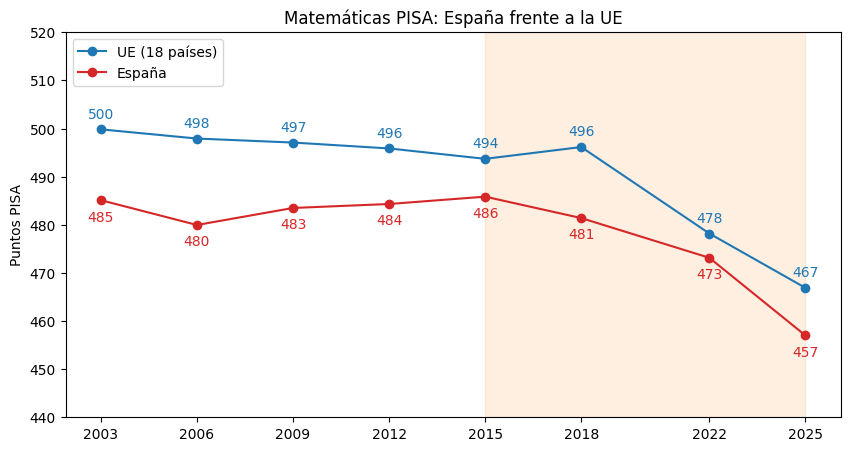

In [62]:

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(comparacion_m.index, comparacion_m['UE'], marker='o', label=f'UE ({len(completos_m)} países)')
ax.plot(comparacion_m.index, comparacion_m['España'], marker='o', color='tab:red', label='España')
ax.axvspan(2015, 2025, color='tab:orange', alpha=0.12)   # periodo de análisis
for anio, nota in comparacion_m['España'].items():
    ax.annotate(f'{nota:.0f}', (anio, nota), textcoords='offset points', xytext=(0, -15), ha='center', color='tab:red')
for anio, nota in comparacion_m['UE'].items():
    ax.annotate(f'{nota:.0f}', (anio, nota), textcoords='offset points', xytext=(0, 8), ha='center', color='tab:blue')
ax.set_ylim(440, 520)
ax.set_xticks(comparacion_m.index)
ax.set_title('Matemáticas PISA: España frente a la UE')
ax.set_ylabel('Puntos PISA')
ax.legend()
plt.show()